# Data Understanding and Preparation
Covers **Stage 1 + 2.1.** Complete every `# TODO` in this notebook **and** in the `src/` modules it imports. 
- Each stage opens with a **sub-task checklist**
- Capture any repo-generated evidence (MLflow UI, Docker build, CI run, drift report) as screenshots/summaries **inside the notebook/report**.

**File ownership** — 
- *Provided (no change):* `config.py`. 
- *Provided to extend:* `src/data_prep.py` (function stubs). 
- *You build:* this notebook + the report.

Prereqs: `pip install -r requirements.txt`; extract the Kaggle casting dataset under `data/` (train/test → ok_front/def_front).

### 0. Setup

In [12]:
from pathlib import Path
from os.path import join
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
import config
from src import data_prep
# TODO: print config.CLASS_TO_IDX and config.POSITIVE_CLASS to confirm setup
print(config.CLASS_TO_IDX)
print(config.POSITIVE_CLASS)

{'ok_front': 0, 'def_front': 1}
def_front


## **Stage 1.1 — Business & Data Understanding** <font color="red">[5 marks]</font>

- **1.1.1 — Business objective & justification [2]** — *to be done in the report*
- **1.1.2 — Success metric choice (recall/F1 on defects) [2]** — *to be done in the report*
- **1.1.3 — Dataset structure & class understanding [1]**

**Objective:** Understand the problem + dataset and name the right metric.

**Implement in:** this notebook (+ src/data_prep.find_data_root, list_images)

**Inputs → Outputs:** data/ images → counts + class distribution per split

**TODO:** locate the data root; count images per class per split; plot the distribution; state that defect = positive class and recall-on-defects (not accuracy) is the headline metric.

**Document here:** 1.1.1/1.1.2 in the report; 1.1.3 here (dataset structure).

Data root: D:\py_test\data_files\Capstone\upGrad-MLOps-Capstone\data\casting_data
train split: ok_front class count 2875, def_front class count 3758
test split: ok_front class count 262, def_front class count 453
Total Images: 7348
Positive Clas: def_front
Total Classes: ['ok_front', 'def_front']
Total Classes Count: 2 



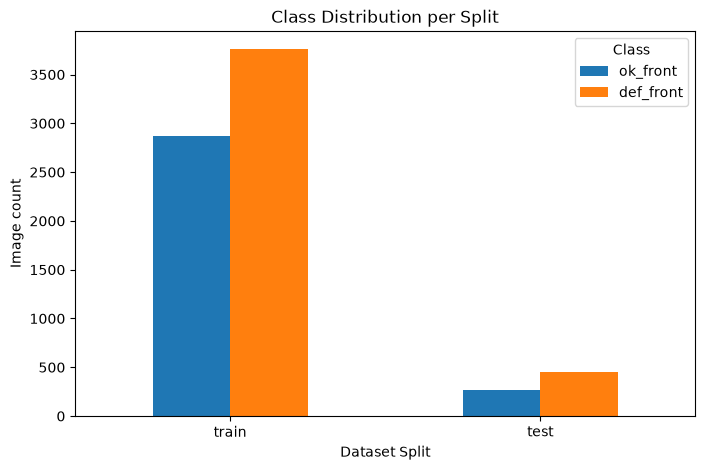

In [13]:
# TODO 1.1.3: root = data_prep.find_data_root(); count + plot class distribution by split

#  locate the data root
root = data_prep.find_data_root()
print(f"Data root: {root}")

# count images per class per split
total_counts = {}
total = 0
for split in ("train", "test"):
    ok_count = []
    defect_count = []
    all_images = data_prep.list_images(Path(root, split))
    if len(all_images) > 0:
        for img_path, cls in all_images:
            if cls == 0:
                ok_count.append(img_path)

            if cls == 1:
                defect_count.append(img_path)        
    else:
        raise FileNotFoundError(f"No data found for the {split} split")

    total_counts[split] = {config.IDX_TO_CLASS[0]: len(ok_count), config.IDX_TO_CLASS[1]: len(defect_count)}

    print(f"{split} split: ok_front class count {len(ok_count)}, def_front class count {len(defect_count)}")

    total += len(ok_count) + len(defect_count)

print("Total Images:", total)
print("Positive Clas:", config.POSITIVE_CLASS)
print("Total Classes:", config.CLASSES)
print("Total Classes Count:", len(config.CLASSES), "\n")

# plot the distribution
class_df = pd.DataFrame(total_counts).T
class_df.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Dataset Split")
plt.ylabel("Image count")
plt.title("Class Distribution per Split")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.show()

## **Stage 1.2 — Data Quality Validation** <font color="red">[5 marks]</font>

- **1.2.1 — Corrupt-file & image-dimension checks [2]**
- **1.2.2 — Duplicate detection (hashing) — leakage guard [2]**
- **1.2.3 — Class distribution + pass/fail report [1]**

**Objective:** Programmatically validate image quality before any split.

**Implement in:** src/data_prep.validate_quality

**Inputs → Outputs:** data root → a pass/fail report dict (corrupt, duplicates, dimensions, distribution)

**TODO:** check missing/corrupt files (Image.verify) and dimensions (1.2.1); detect DUPLICATE images via md5/hash (1.2.2); quantify class balance + print a pass/fail report (1.2.3); expect ~7,348 images, ~64 duplicates.

**Document here:** the quality report + why duplicate detection prevents train/test leakage.

In [14]:
# TODO 1.2.1-1.2.3: qc = data_prep.validate_quality(root); print(qc['total_images'], qc['passed'])

qc = data_prep.validate_quality(root)
print("Total Images:", qc['total_images'])
print("Passed:", qc['passed'])
print("Class distribution:", qc['class_distribution'])
print("Corrput files:", len(qc['corrupt_files']))
print("Bad dimentions:", len(qc['bad_dimensions']))
print("Duplicates:", len(qc['duplicates']))

print("\nWhy duplicate detection prevents train/test leakage?")
print(f"""
Duplicates across train/test splits cause leakage, inflating metrics unrealistically. Hashing ensures leakage-safety.
Even if duplicates inflate accuracy, recall on defects is the true business metric.

Duplicate images were detected via md5 hashing (~{len(qc['duplicates'])} duplicates). 
These are flagged in the quality report but not deleted, since the requirement was detection only. 
The rationale is to highlight potential train/test leakage, which can inflate metrics. 
Later stages proceed with the dataset intact, but the report notes why duplicates matter.
""")

Total Images: 7348
Passed: False
Class distribution: {'train': {'ok_front': 2875, 'def_front': 3758}, 'test': {'ok_front': 262, 'def_front': 453}}
Corrput files: 0
Bad dimentions: 0
Duplicates: 64

Why duplicate detection prevents train/test leakage?

Duplicates across train/test splits cause leakage, inflating metrics unrealistically. Hashing ensures leakage-safety.
Even if duplicates inflate accuracy, recall on defects is the true business metric.

Duplicate images were detected via md5 hashing (~64 duplicates). 
These are flagged in the quality report but not deleted, since the requirement was detection only. 
The rationale is to highlight potential train/test leakage, which can inflate metrics. 
Later stages proceed with the dataset intact, but the report notes why duplicates matter.



## **Stage 1.3 — Dataset Versioning & Metadata** <font color="red">[5 marks]</font>

- **1.3.1 — Reproducible, stratified train/val/test split [3]**
- **1.3.2 — Split snapshot + metadata.json (versioning) [2]**

**Objective:** Create reproducible, versioned splits.

**Implement in:** src/data_prep.build_splits

**Inputs → Outputs:** data root + version id → train/val/test file lists + metadata.json

**TODO:** make a STRATIFIED train/val/test split (seed 42) (1.3.1); snapshot the file lists + write metadata.json (version id, date, class defs, split sizes, seed) (1.3.2).

**Document here:** the split sizes + the metadata record.

In [15]:
# TODO 1.3.1-1.3.2: meta = data_prep.build_splits(root, 'v1'); print(meta['split_info'])
meta = data_prep.build_splits(root, 'v1')
print(json.dumps(meta['split_info'], indent=2))

print("""
We created reproducible stratified splits with a fixed seed to preserve class balance.
Each split was snapshot into JSON files, and metadata.json records version, date, class definitions, and split sizes.
This ensures auditability and leakage-safety.
""")

{
  "train": {
    "ok_front": 2444,
    "def_front": 3194
  },
  "val": {
    "ok_front": 431,
    "def_front": 564
  },
  "test": {
    "ok_front": 262,
    "def_front": 453
  }
}

We created reproducible stratified splits with a fixed seed to preserve class balance.
Each split was snapshot into JSON files, and metadata.json records version, date, class definitions, and split sizes.
This ensures auditability and leakage-safety.



## **Stage 1.4 — EDA & Methodology Design** <font color="red">[5 marks]</font>

- **1.4.1 — Image-characteristic EDA [3]** — *to be done in this notebook and the report*
- **1.4.2 — End-to-end MLOps workflow design [2]** — *to be done in the report*

**Objective:** Explore image characteristics that motivate preprocessing + drift features.

**Implement in:** this notebook (+ src/data_prep.image_features)

**Inputs → Outputs:** sample images → a feature table (brightness/contrast/edge/sharpness/dark-ratio) by class

**TODO:** show a sample grid (OK vs Defective) + per-class feature means (1.4.1); in the report, design the end-to-end MLOps workflow (1.4.2).

**Document here:** an interpretation cell (1.4.1) + the workflow design in the report (1.4.2).

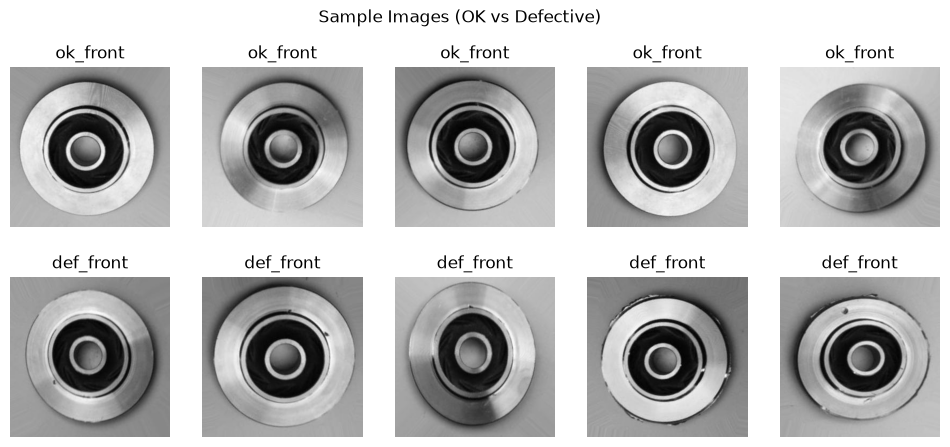


Class: ok_front
brightness        149.776566
contrast           62.416275
edge_density        0.040712
sharpness         867.291032
mean_intensity    149.776566
dtype: float64

Class: def_front
brightness        138.657409
contrast           58.015182
edge_density        0.041129
sharpness         841.117218
mean_intensity    138.657409
dtype: float64

1.4.1: Interpretation:

- OK vs Dfective images differ in brightness, contrast, and sharpness. Defective castings often show irregular textures (higher edge density, lower sharpness).
- These features motivate preprocessing choices (normalisation, augmentation) and later serve as drift signals in Stage 4.
- By quantifying per-class feature means, you establish a baseline distribution that Evidently + PSI will monitor in production

1.4.2: end-to-end MLOps workflow

Stage 1: Data validation, versioning, EDA.
Stage 2: Preprocessing, tansfer learning, MLflow tracing.
Stage 3: Evaluation, registry, FastAPI/Docker/CI.
Stage 4: Monitoring (st

In [16]:
# TODO 1.4.1: sample-image grid; per-class image_features means

# Collect images from train split
get_images = data_prep.list_images(Path(root, "train"))
ok_images = [(p, cls) for p, cls in get_images if cls == 0]
defect_images = [(p, cls) for p, cls in get_images if cls == 1]

# sample-image grid
per_split_sample = 5
fig, axes = plt.subplots(2, per_split_sample, figsize=(12, 5))
for i, (img_path, cls) in enumerate(ok_images[:per_split_sample] + defect_images[:per_split_sample]):
    img = Image.open(img_path)
    axes[i//per_split_sample, i%per_split_sample].imshow(img, cmap="gray")
    axes[i//per_split_sample, i%per_split_sample].set_title(config.IDX_TO_CLASS[cls])
    axes[i//per_split_sample, i%per_split_sample].axis("off")
plt.suptitle("Sample Images (OK vs Defective)")
plt.show()

# Compute per-class 
features_by_class = {c:[] for c in config.CLASSES}
for img_path, cls in ok_images[:100] + defect_images[:100]:
    img = Image.open(img_path)
    feats = data_prep.image_features(img)
    features_by_class[config.IDX_TO_CLASS[cls]].append(feats)

# Aggregate means
for cls, feats in features_by_class.items():
    feats_df = pd.DataFrame(feats)
    print(f"\nClass: {cls}")
    print(feats_df.mean())

print("\n1.4.1: Interpretation:")
print("""
- OK vs Dfective images differ in brightness, contrast, and sharpness. Defective castings often show irregular textures (higher edge density, lower sharpness).
- These features motivate preprocessing choices (normalisation, augmentation) and later serve as drift signals in Stage 4.
- By quantifying per-class feature means, you establish a baseline distribution that Evidently + PSI will monitor in production
""")

print("1.4.2: end-to-end MLOps workflow")
print("""
Stage 1: Data validation, versioning, EDA.
Stage 2: Preprocessing, tansfer learning, MLflow tracing.
Stage 3: Evaluation, registry, FastAPI/Docker/CI.
Stage 4: Monitoring (statistical + embedding drift), retraining, rollback governance.
""")

## **Stage 2.1 — Preprocessing & Augmentation** <font color="red">[6 marks]</font>

- **2.1.1 — Convert greyscale image to 3-channel RGB, resize 224, ImageNet normalise [3]**
- **2.1.2 — Train-only augmentation (val/test none) [3]**

**Objective:** Build transforms that match the pretrained ResNet18 backbone.

**Implement in:** src/data_prep.get_transforms

**Inputs → Outputs:** a PIL image → a (3,224,224) normalised tensor; train transform adds augmentation

**TODO:** Convert greyscale image to 3-channel RGB, Resize 224, ImageNet normalise (2.1.1); train-time augmentation (flip/rotation/translate/colour jitter) with val/test NO augmentation (2.1.2).

**Document here:** a before/after visualisation of the transforms.

Tensor shape: torch.Size([3, 224, 224])


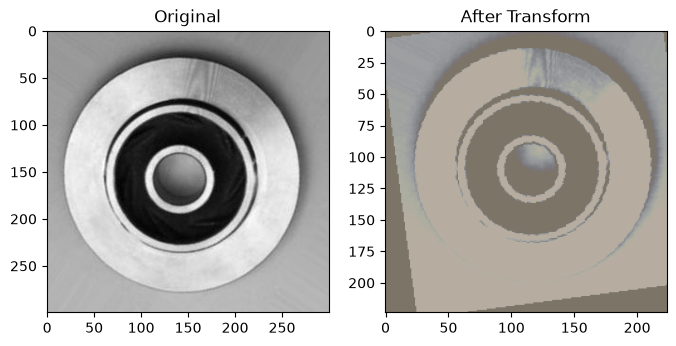

In [17]:
# TODO 2.1.1-2.1.2: tf=data_prep.get_transforms(train=True); verify a sample tensor is (3,224,224)

# Build transforms that match the pretrained ResNet18 backbone.
tf = data_prep.get_transforms(train=True)

# Verify a sample tensor is (3,224,224)
sample_img = Image.open(ok_images[0][0])
tensor = tf(sample_img)
print("Tensor shape:", tensor.shape)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
# Before visualisation of the transforms
axes[0].imshow(sample_img, cmap="gray")
axes[0].set_title("Original")

# After visualisation of the transforms
aug_img = tf(sample_img).permute(1, 2, 0).numpy()
axes[1].imshow((aug_img * config.IMAGENET_STD + config.IMAGENET_MEAN).clip(0,1))
axes[1].set_title("After Transform")
plt.show()

---
**Outputs feed Stage 2.2+** in `Model_Development_and_Tracking.ipynb` (the versioned splits + transforms are reused to train the model).